In [1]:
import torch

In [6]:
def get_q_scale_symmetric(tesnor,dtype=torch.int8):
    q_max=torch.iinfo(dtype).max
    r_max=tesnor.abs().max().item()

    return r_max/q_max
    
    

In [7]:
test_torch=torch.randn((4,4))

In [9]:
test_torch

tensor([[ 0.8741,  0.7900,  1.9779, -1.4155],
        [-0.6238,  0.3105,  0.3332, -2.1727],
        [-0.6808, -1.4841, -0.5747, -1.9346],
        [ 0.2900, -0.1723, -0.8134, -0.0501]])

In [8]:
get_q_scale_symmetric(tesnor=test_torch)

0.017107912874597266

In [10]:
from helper import linear_q_with_scale_and_zero_point

In [24]:
def linear_q_symmetric(tensor,dtype=torch.int8):
    scale = get_q_scale_symmetric(tensor)
    quantized_tensor = linear_q_with_scale_and_zero_point(tensor,scale=scale,zero_point=0 , dtype=dtype)
    
    return quantized_tensor, scale



In [25]:
quantized_tensor, scale =linear_q_symmetric(test_torch)

In [26]:
quntized_tensor

tensor([[  51,   46,  116,  -83],
        [ -36,   18,   19, -127],
        [ -40,  -87,  -34, -113],
        [  17,  -10,  -48,   -3]], dtype=torch.int8)

In [27]:
from helper import linear_dequantization,plot_quantization_errors

In [32]:
dequantized_tensor=linear_dequantization(quantized_tensor,scale=scale, zero_point=0)

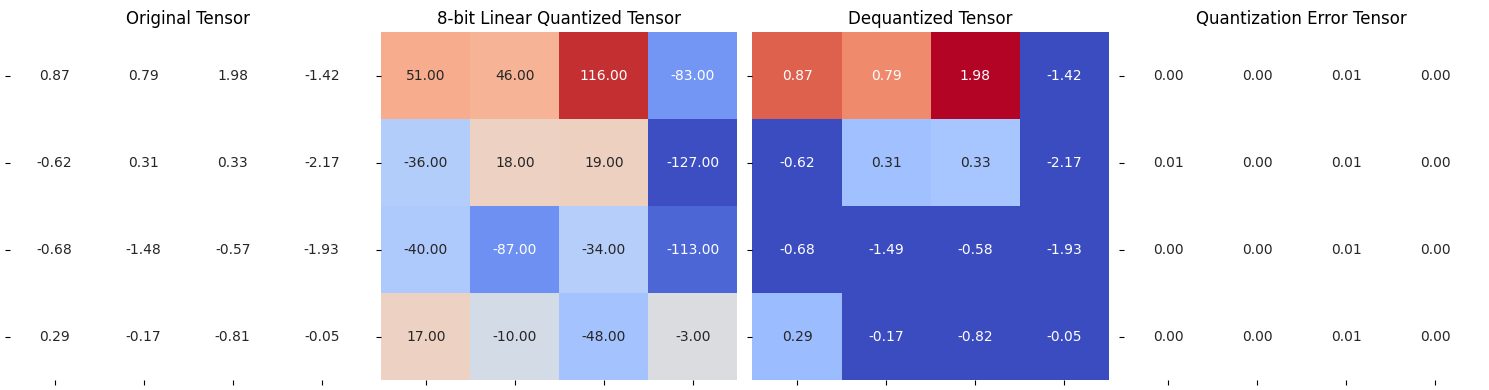

In [33]:
plot_quantization_errors(dequantized_tensor=dequantized_tensor , original_tensor=test_torch , quantized_tensor=quantized_tensor)

In [34]:
(dequantized_tensor-test_torch).square().mean()

tensor(2.2353e-05)